# Trabajo Práctico: Predicción de lluvia en Australia

**Aprendizaje Automático 1 - Tecnicatura Universitaria en Inteligencia Artificial (FCEIA)**

Integrantes:
* Federico Arias
* Guillermina Bousoño

El objetivo del trabajo es construir y poner en producción un modelo de clasificación binaria capaz de predecir, a las 23:59 hs de cada día, si al día siguiente lloverá o no (`RainTomorrow`) a partir de registros meteorológicos diarios de distintas estaciones de Australia.

---

# 1. Análisis descriptivo y preprocesamiento

## 1.1 Configuración del entorno e inspección inicial

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('weatherAUS_2026C2.csv')
print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
display(df.head())
df.info()

Dimensiones: 145412 filas x 25 columnas


,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        145412 non-null  int64  
 1   Date              145412 non-null  str    
 2   Location          145412 non-null  str    
 3   MinTemp           143928 non-null  float64
 4   MaxTemp           144159 non-null  float64
 5   Rainfall          142152 non-null  float64
 6   Evaporation       82658 non-null   float64
 7   Sunshine          75616 non-null   float64
 8   WindGustDir       135096 non-null  str    
 9   WindGustSpeed     135159 non-null  float64
 10  WindDir9am        134850 non-null  str    
 11  WindDir3pm        141186 non-null  str    
 12  WindSpeed9am      143645 non-null  float64
 13  WindSpeed3pm      142351 non-null  float64
 14  Humidity9am       142759 non-null  float64
 15  Humidity3pm       140907 non-null  float64
 16  Pressure9am       130351 non-nu

### Descripción de las variables y primer descarte estructural

El dataset releva mediciones diarias (temperaturas, lluvia, viento, humedad, presión y nubosidad medidas a las 9 am y a las 3 pm) junto con la ubicación de la estación (`Location`) y la fecha (`Date`).

Antes de iniciar el análisis estadístico, realizamos tres ajustes estructurales sobre la tabla:
1. **`Unnamed: 0`:** Es una columna de índice redundante generada al exportar el CSV, por lo que se descarta.
2. **Prevención de *Data Leakage* (`RainfallTomorrow`):** La columna `RainfallTomorrow` registra cuántos milímetros llovió efectivamente al día siguiente. Como ese dato ocurre en el futuro respecto del momento de la predicción (23:59 hs del día actual) y determina directamente a `RainTomorrow`, conservarla como predictora provocaría una fuga de información (*data leakage*). Se elimina del conjunto de características.
3. **Filas sin variable objetivo (`RainTomorrow`):** En un problema supervisado no tiene sentido imputar la etiqueta que queremos aprender a predecir, por lo que descartamos los registros donde `RainTomorrow` es nulo (~2.2% del total). También ajustamos el tipo de la columna `Date` a formato fecha (`datetime`).

In [4]:
filas_iniciales = len(df)

# Descarte de índice redundante y de variable con información del futuro (Data Leakage)
cols_descartar = [c for c in ['Unnamed: 0', 'RainfallTomorrow'] if c in df.columns]
df = df.drop(columns=cols_descartar)

# Descarte de filas sin target y conversión de fecha
sin_target = df['RainTomorrow'].isna().sum()
df = df.dropna(subset=['RainTomorrow']).reset_index(drop=True)
df['Date'] = pd.to_datetime(df['Date'])

print(f'Columnas descartadas: {cols_descartar}')
print(f'Filas eliminadas por no tener target (RainTomorrow): {sin_target}')
print(f'Dimensiones del dataset de trabajo: {df.shape[0]} filas x {df.shape[1]} columnas')
print(f'Rango temporal: {df["Date"].min().date()} a {df["Date"].max().date()} ({df["Location"].nunique()} ciudades)')

Columnas descartadas: ['Unnamed: 0', 'RainfallTomorrow']
Filas eliminadas por no tener target (RainTomorrow): 3259
Dimensiones del dataset de trabajo: 142153 filas x 23 columnas
Rango temporal: 2007-11-01 a 2017-06-24 (49 ciudades)


| Variable | Tipo | Descripcion |
|----------|------|-------------|
| `Date` | Fecha | día de la observacion |
| `Location` | Categórica nominal | ciudad de la observación |
| `MinTemp` | Numérica continua | temperatura minima del dia |
| `MaxTemp` | Numérica continua | temperatura maxima del dia |
| `Rainfall` | Numérica continua | lluvia caída en el dia |
| `Evaporation` | Numérica continua | evaporacion en 24 hs (mm) |
| `Sunshine` | Numérica continua | Horas de sol en el dia |
| `WindGustDir` | Categorica nominal | dirección de la rafaga de viento mas fuerte |
| `WindGustSpeed` | Numerica continua | velocidad de la rafaga de viento mas fuerte |
| `WindDir9am` | Categorica nominal | direccion media del viento a las 9am |
| `WindDir3pm` | Categorica nominal | direccion media del viento a las 3pm |
| `WindSpeed9am` | Numérica continua | velocidad media del viento a las 3pm |
| `WindSpeed3pm` | Numérica continua | velocidad media del viento a las 3pm |
| `Humidity9am` | Numérica continua | humedad relativa a las 9am |
| `Humidity3pm` | Numérica continua | humedad relativa a las 3pm |
| `Pressure9am` | Numérica continua | presión atmosférica a las 9am |
| `Pressure3pm` | Numérica continua | presión atmosferica a las 3pm |
| `Cloud9am` | Numérica discreta | nubosidad a las 9 am (0 = despekado, 8 = cubierto) |
| `Cloud3pm` | Numérica discreta | nubosidad a las 9 am (0 = despekado, 8 = cubierto) |
| `Temp9am` | Numérica continua | temperatura a las 9am |
| `Temp3pm` | Numérica continua | temperatura a las 3pm |
| `RainToday` | Categórica binaria | "Yes" si llovió más de 1 mm en el día, "No" en caso contrario |
| `RainTomorrow` | Categórica binaria | "Yes" si mañana llueve más de 1 mm. |
| `RainfallTomorrow` | Numérica continua | milímetros de lluvia del día siguiente |

## 1.2 Análisis de balanceo de la variable objetivo

Analizamos la proporción de clases en `RainTomorrow` antes de definir la estrategia de modelado y evaluación.

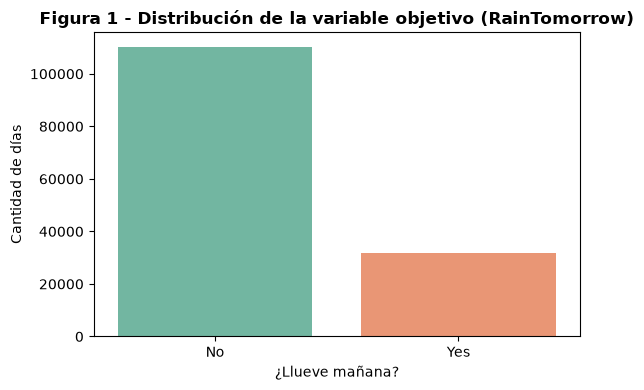

,Frecuencia,Porcentaje (%)
RainTomorrow,,
No,110281,77.58
Yes,31872,22.42


In [5]:
conteo_target = df['RainTomorrow'].value_counts()
pct_target = df['RainTomorrow'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='RainTomorrow', hue='RainTomorrow', palette='Set2', legend=False, ax=ax)
ax.set_title('Figura 1 - Distribución de la variable objetivo (RainTomorrow)', fontweight='bold', fontsize=12)
ax.set_xlabel('¿Llueve mañana?')
ax.set_ylabel('Cantidad de días')
plt.tight_layout()
plt.show()

pd.DataFrame({'Frecuencia': conteo_target, 'Porcentaje (%)': pct_target.round(2)})

**¿Está balanceado el dataset? ¿Por qué importa esta pregunta?**

El dataset está claramente **desbalanceado**: el **77.58%** de los registros corresponde a días en los que no llovió al día siguiente (`No`), frente a solo un **22.42%** de días con lluvia (`Yes`).

Hacerse esta pregunta desde el inicio es clave por dos motivos:
1. **Sesgo en el entrenamiento:** La función de pérdida estándar pondera el error de todas las filas por igual. Como la clase `No` es casi 3.5 veces más frecuente, al modelo le sale "barato" ignorar la clase minoritaria (`Yes`) para minimizar el costo global, corriendo la frontera de decisión y logrando un *Recall* muy bajo en la detección de lluvia. Para corregirlo durante el entrenamiento deberemos aplicar pesos en la función de costo (`class_weight='balanced'`) o técnicas de remuestreo sobre el conjunto de entrenamiento.
2. **Trampa del *Accuracy*:** Con esta distribución, un clasificador trivial que prediga siempre `No` obtendría un *Accuracy* del 77.6% sin haber aprendido a detectar un solo día de lluvia. Por lo tanto, el *Accuracy* por sí solo es engañoso y necesitaremos evaluar los modelos con métricas sensibles a la clase minoritaria como **Recall, Precision, F1-Score y AUC-ROC**.

## 1.3 Estadística descriptiva y comportamiento de las variables

Separamos las variables numéricas de las categóricas para inspeccionar sus rangos de variación, asimetrías y posibles valores fuera de rango.

In [6]:
cols_num = df.select_dtypes(include=[np.number]).columns.tolist()
cols_cat = df.select_dtypes(include=['object', 'string']).columns.drop('RainTomorrow').tolist()

print(f'Variables numéricas ({len(cols_num)}): {cols_num}')
print(f'Variables categóricas ({len(cols_cat)}): {cols_cat}\n')

# Resumen estadístico de las variables numéricas
desc_num = df[cols_num].describe().T
desc_num['mediana'] = df[cols_num].median()
desc_num['skew'] = df[cols_num].skew()
display(desc_num[['count', 'mean', 'mediana', 'std', 'min', '25%', '50%', '75%', 'max', 'skew']].round(2))

# Resumen de las variables categóricas
display(df[cols_cat + ['RainTomorrow']].describe().T)

Variables numéricas (16): ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']
Variables categóricas (5): ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']



,count,mean,mediana,std,min,25%,50%,75%,max,skew
MinTemp,141516.0,12.19,12.0,6.42,-9.7,7.6,12.0,16.8,34.1,0.02
MaxTemp,141831.0,23.23,22.6,7.13,-5.1,17.9,22.6,28.2,49.1,0.22
Rainfall,140747.0,2.35,0.0,8.47,0.0,0.0,0.0,0.8,371.0,9.89
Evaporation,81341.0,5.47,4.8,4.19,0.0,2.6,4.8,7.4,145.0,3.75
Sunshine,74368.0,7.62,8.5,3.78,0.0,4.9,8.5,10.6,14.5,-0.50
WindGustSpeed,132885.0,39.99,38.0,13.63,6.0,31.0,38.0,48.0,135.0,0.87
WindSpeed9am,140805.0,14.03,13.0,8.91,0.0,7.0,13.0,19.0,130.0,0.79
WindSpeed3pm,139524.0,18.64,18.0,8.86,0.0,12.0,18.0,24.0,86.0,0.62
Humidity9am,140379.0,68.82,69.9,19.09,0.0,56.9,69.9,83.1,100.0,-0.48
Humidity3pm,138544.0,51.48,51.9,20.85,0.0,36.5,51.9,65.6,100.0,0.03


,count,unique,top,freq
Location,142153,49,Canberra,3417
WindGustDir,132825,16,W,9775
WindDir9am,132144,16,N,11389
WindDir3pm,138377,16,SE,10662
RainToday,140747,2,No,109296
RainTomorrow,142153,2,No,110281


### Caracterización estadística de las variables

A partir de la exploración de las dimensiones numéricas y categóricas, se identifican los siguientes patrones:

* **Comportamiento de las variables numéricas:**
  * **Simetría en variables térmicas y barométricas:** Las temperaturas (`MinTemp`, `MaxTemp`, `Temp9am`, `Temp3pm`) y las presiones atmosféricas (`Pressure9am`, `Pressure3pm`) presentan coeficientes de asimetría (*skewness*) cercanos a cero ($\vert{}skew\vert{} < 0.25$) y una coincidencia casi exacta entre sus medias y medianas, lo cual refleja distribuciones aproximadamente normales.
  * **Asimetría pronunciada y dispersión:** La variable `Rainfall` presenta un sesgo positivo severo ($skew = 9.89$), con una mediana de $0.0\text{ mm}$ y un valor atípico máximo de $371.0\text{ mm}$, propio de eventos de precipitación extrema concentrados en colas pesadas. Un comportamiento similar se observa en `Evaporation` ($skew = 3.75$).
  * **Heterogeneidad de escalas:** Las magnitudes físicas presentan rangos no comparables (la presión atmosférica promedia $\approx 1016\text{ hPa}$, mientras que la nubosidad varía entre $0$ y $9$ octas), lo que hace indispensable estandarizar las características numéricas en el pipeline de preprocesamiento para no distorsionar los pesos de los modelos lineales ni la convergencia de optimizadores basados en gradientes.

* **Comportamiento de las variables categóricas:**
  * `Location` abarca 49 estaciones meteorológicas distribuidas en Australia (siendo Canberra la de mayor frecuencia con 3417 observaciones).
  * Las direcciones del viento (`WindGustDir`, `WindDir9am`, `WindDir3pm`) cuentan con 16 categorías correspondientes a la rosa de los vientos de 16 rumbos.
  * `RainToday` es una variable dicotómica que refleja la precipitación acumulada en la jornada previa ($> 1\text{ mm}$). Junto con la variable objetivo `RainTomorrow`, se codificarán en valores binarios ($0$ y $1$).

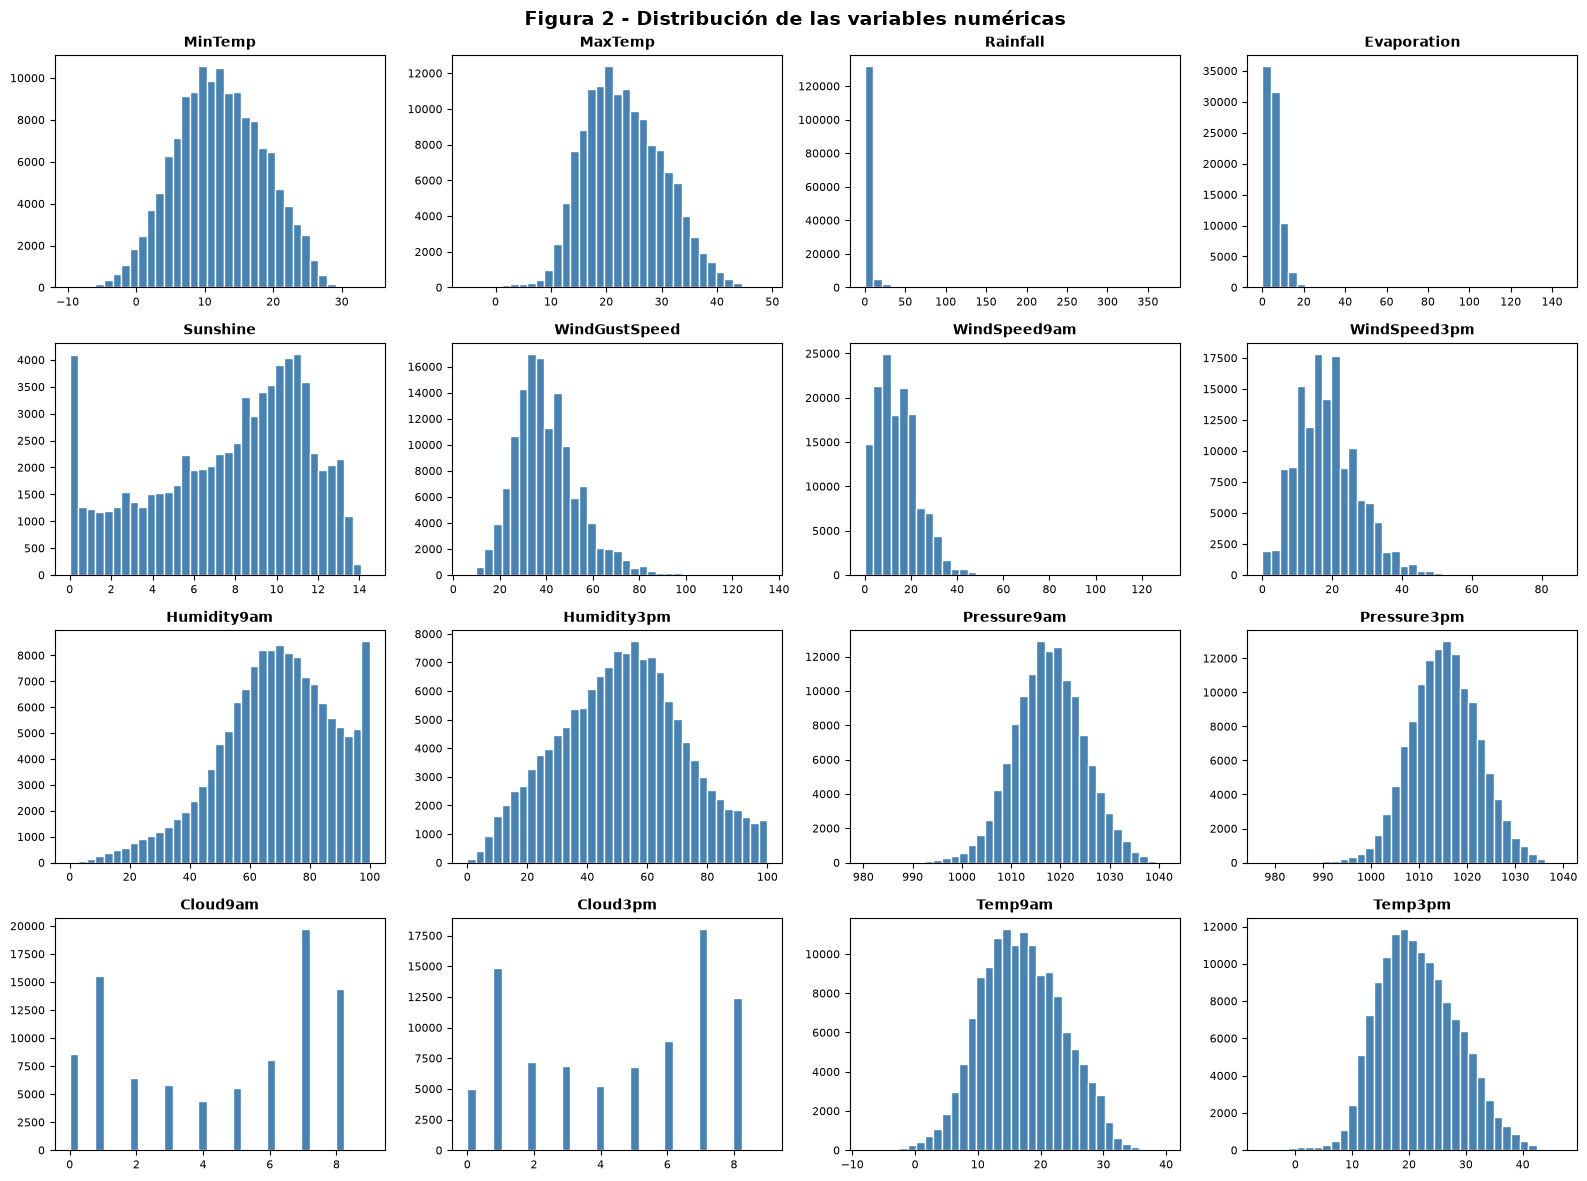

In [7]:
# Histogramas de las variables numéricas
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(cols_num):
    axes[i].hist(df[col].dropna(), bins=35, color='steelblue', edgecolor='white')
    axes[i].set_title(col, fontsize=10, fontweight='bold')
    axes[i].tick_params(labelsize=8)

for j in range(len(cols_num), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Figura 2 - Distribución de las variables numéricas', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

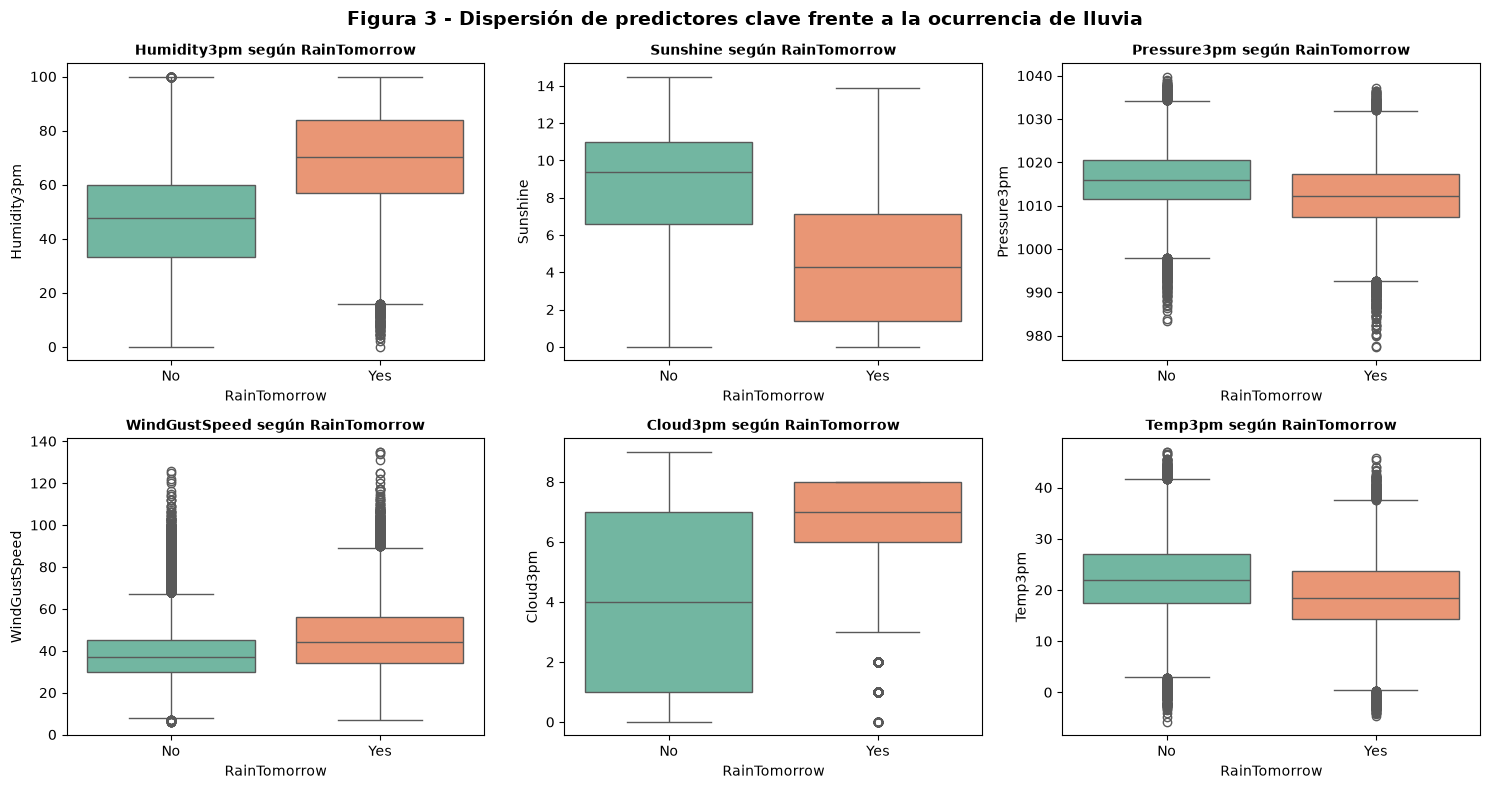

In [8]:
# Boxplots de predictores relevantes discriminados por la variable objetivo
vars_clave = ['Humidity3pm', 'Sunshine', 'Pressure3pm', 'WindGustSpeed', 'Cloud3pm', 'Temp3pm']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(vars_clave):
    sns.boxplot(data=df, x='RainTomorrow', y=col, hue='RainTomorrow', palette='Set2', legend=False, ax=axes[i])
    axes[i].set_title(f'{col} según RainTomorrow', fontsize=10, fontweight='bold')
    axes[i].set_xlabel('RainTomorrow')

plt.suptitle('Figura 3 - Dispersión de predictores clave frente a la ocurrencia de lluvia', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

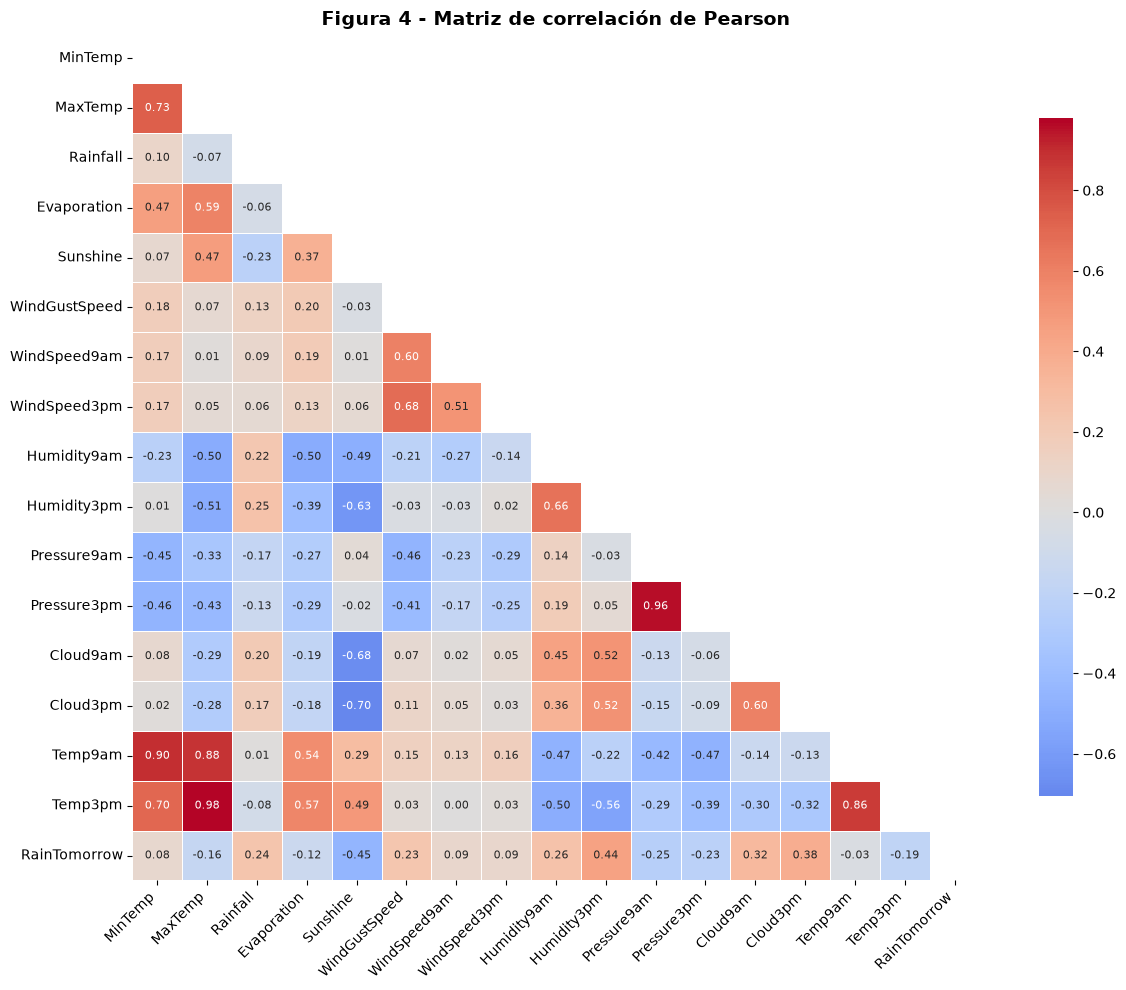

In [9]:
# Matriz de correlación lineal de Pearson (incluyendo target binarizado temporalmente)
df_corr = df[cols_num].copy()
df_corr['RainTomorrow'] = (df['RainTomorrow'] == 'Yes').astype(int)

corr = df_corr.corr()

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8}, annot_kws={'size': 8}, ax=ax)
ax.set_title('Figura 4 - Matriz de correlación de Pearson', fontweight='bold', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Interpretación de correlaciones y colinealidad:**

* **Relación con la variable objetivo (`RainTomorrow`):** 
  * Los predictores con mayor correlación lineal respecto a la lluvia del día siguiente son la humedad relativa a las 3 pm (`Humidity3pm`, $r \approx 0.45$), la nubosidad a las 3 pm (`Cloud3pm`, $r \approx 0.38$) y las horas de brillo solar (`Sunshine`, correlación inversa $r \approx -0.45$).
  * En contraste, variables como `MinTemp` o `WindSpeed9am` muestran una asociación lineal débil con el evento de lluvia ($\vert{}r\vert{} < 0.15$).

* **Colinealidad entre pares de predictores:**
  * Se observan correlaciones muy elevadas entre pares de mediciones de una misma magnitud física tomadas en horarios distintos o extremos del día: `Temp9am` y `MinTemp` ($r \approx 0.90$), `Temp3pm` y `MaxTemp` ($r \approx 0.98$), así como `Pressure9am` y `Pressure3pm` ($r \approx 0.96$).
  * Esta redundancia de información introduce colinealidad. Si bien modelos regularizados como la Regresión Logística con penalización $L_2$ o redes neuronales pueden convivir con estas dependencias, en fases de selección de características se considerará si es conveniente retener solo una de las lecturas horarias o construir variables agregadas (como la amplitud térmica diaria `MaxTemp - MinTemp` o el gradiente de presión).

## 1.4 Diagnóstico y tratamiento de valores faltantes

Se analiza el volumen y distribución de datos ausentes en cada variable sobre los 142.153 registros con variable objetivo válida.

In [10]:
# Reporte detallado de datos faltantes
nulos = df.isnull().sum()
pct_nulos = (nulos / len(df)) * 100
df_nulos = pd.DataFrame({'Valores Nulos': nulos, 'Porcentaje (%)': pct_nulos})
df_nulos = df_nulos[df_nulos['Valores Nulos'] > 0].sort_values(by='Porcentaje (%)', ascending=False)
display(df_nulos.round(2))

,Valores Nulos,Porcentaje (%)
Sunshine,67785,47.68
Evaporation,60812,42.78
Cloud3pm,57076,40.15
Cloud9am,53641,37.73
Pressure9am,14010,9.86
Pressure3pm,13977,9.83
WindDir9am,10009,7.04
WindGustDir,9328,6.56
WindGustSpeed,9268,6.52
WindDir3pm,3776,2.66


### Criterios de tratamiento de valores faltantes

De acuerdo con el análisis del reporte, los datos faltantes se estructuran en tres grupos diferenciados:

1. **Variables con ausencia crítica ($>35\%$):** `Sunshine` ($47.68\%$), `Evaporation` ($42.78\%$), `Cloud3pm` ($40.15\%$) y `Cloud9am` ($37.73\%$) presentan una omisión sustancial. Este fenómeno no responde a un mecanismo de pérdida completamente aleatorio (*Missing Completely at Random* - MCAR), sino a limitaciones estructurales de equipamiento en numerosas estaciones meteorológicas del *Bureau of Meteorology* australiano que carecen de heliógrafos o tanques evaporímetros estandarizados (*Missing Not at Random* - MNAR). Imputar más del 40% de los datos mediante métodos simples como la media o la mediana distorsionaría severamente la varianza real de las variables.
2. **Variables con ausencia moderada ($5\%$ a $10\%$):** Presiones atmosféricas (`Pressure9am`, `Pressure3pm`) y ráfagas máximas de viento (`WindGustDir`, `WindGustSpeed`).
3. **Variables con ausencia reducida ($<3\%$):** Temperaturas, mediciones de viento a las 9 am/3 pm, humedad y `RainToday`.

**Estrategia metodológica:**
Para evitar la pérdida de más del 60% del dataset que implicaría una eliminación por listas (*listwise deletion*), se preservan las observaciones y se aplicará **imputación**:
* Imputación basada en la mediana para variables numéricas (robusta frente a la asimetría de variables como `Rainfall`).
* Imputación por la moda (o categoría explícita `Missing`) para variables categóricas.
* **Preservación contra la fuga de datos (*Data Leakage*):** Todos los valores de imputación (medianas y modas) se calcularán **exclusivamente sobre el conjunto de entrenamiento (`train`)** y se aplicarán sobre validación y prueba sin recalcular parámetros.